<a href="https://colab.research.google.com/github/GeiseEduardo1973/Engenharia-de-Software-Ci-ncia-da-Computa-o/blob/main/Redes_Neurais_Convolucionais.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Formato dos dados de treino: (60000, 28, 28)
Formato dos dados de teste: (10000, 28, 28)


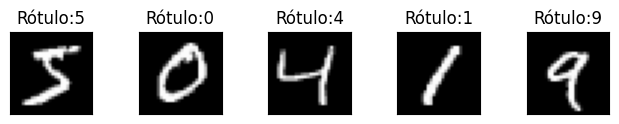

Formato da Imagem: (28, 28, 1)
Conjunto de Treinamento: 55000 registros
Conjunto de Validação: 5000 registros
Conjunto de Testes: 10000 registros
Novo formato de x_treino: (32, 32, 1)
Novo formato de x_validacao: (32, 32, 1)
Novo formato de x_teste: (32, 32, 1)
Normalização concluída com sucesso!


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_35 (Conv2D)              │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_26            │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_27            │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

... (4 outputs left out)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

Epoch 1/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 33s 76ms/step - accuracy: 0.9765 - loss: 0.0778 - val_accuracy: 0.9788 - val_loss: 0.0783
Epoch 2/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 39s 71ms/step - accuracy: 0.9775 - loss: 0.0747 - val_accuracy: 0.9802 - val_loss: 0.0729
Epoch 3/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 31s 73ms/step - accuracy: 0.9781 - loss: 0.0715 - val_accuracy: 0.9778 - val_loss: 0.0821
Epoch 4/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 30s 69ms/step - accuracy: 0.9795 - loss: 0.0691 - val_accuracy: 0.9806 - val_loss: 0.0701
Epoch 5/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 30s 70ms/step - accuracy: 0.9803 - loss: 0.0660 - val_accuracy: 0.9804 - val_loss: 0.0677
Epoch 6/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 41s 69ms/step - accuracy: 0.9806 - loss: 0.0648 - val_accuracy: 0.9824 - val_loss: 0.0650
Epoch 7/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 30s 71ms/step - accuracy: 0.9807 - loss: 0.0631 - val_accuracy: 0.9814 - val_loss: 0.0688
Epoch 8/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 30s 71ms/step - accuracy: 0.9815 - loss: 0.0611 - 

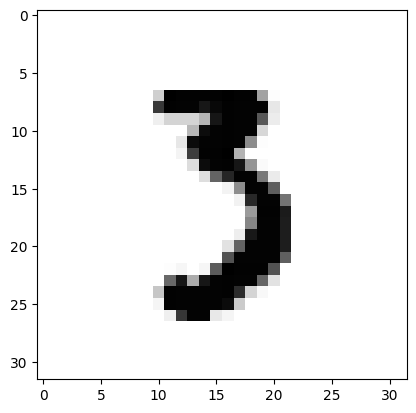

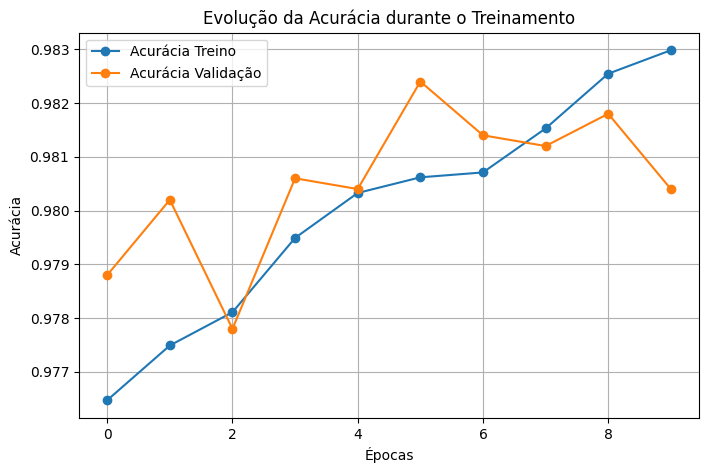

In [34]:
import tensorflow as tf

# Carregando a base de dados MNIST (já dividida em treino e teste)
(x_treino, y_treino), (x_teste, y_teste) = tf.keras.datasets.mnist.load_data()

# Verificando o formato dos dados carregados
print("Formato dos dados de treino:", x_treino.shape)
print("Formato dos dados de teste:", x_teste.shape)

import matplotlib.pyplot as plt

for i in range(5):
  plt.subplot(1, 5, i+1)
  plt.subplot(1, 5, i+1)
  plt.tight_layout()
  plt.imshow(x_treino[i].reshape(28, 28), cmap='gray')
  plt.title('Rótulo:{}'.format(y_treino[i]))
  plt.xticks([])
  plt.yticks([])
plt.show()

import numpy as np

quantidade_dados_treino = 55000

# 1. Separando os 55.000 para treino e os 5.000 restantes para validação
x_validacao = x_treino[quantidade_dados_treino:]
y_validacao = y_treino[quantidade_dados_treino:]

x_treino = x_treino[:quantidade_dados_treino]
y_treino = y_treino[:quantidade_dados_treino]

# 2. Adicionando a dimensão do canal (necessário para CNNs: de 28x28 para 28x28x1)
x_treino = x_treino[..., np.newaxis]
x_validacao = x_validacao[..., np.newaxis]
x_teste = x_teste[..., np.newaxis]

# 3. Imprimindo os resultados atualizados
print('Formato da Imagem:', x_treino[0].shape)
print('Conjunto de Treinamento:', len(x_treino), 'registros')
print('Conjunto de Validação:', len(x_validacao), 'registros')
print('Conjunto de Testes:', len(x_teste), 'registros')

# Aplicando o padding (preenchimento com zeros) para transformar de 28x28 para 32x32
# O formato do pad será: ((antes, depois para eixo 0), (antes, depois para eixo 1), (antes, depois para eixo 2))
# Adicionamos 2 pixels em cima, 2 embaixo, 2 à esquerda e 2 à direita (2 + 28 + 2 = 32)

x_treino = np.pad(x_treino, ((0, 0), (2, 2), (2, 2), (0, 0)), mode='constant')
x_validacao = np.pad(x_validacao, ((0, 0), (2, 2), (2, 2), (0, 0)), mode='constant')
x_teste = np.pad(x_teste, ((0, 0), (2, 2), (2, 2), (0, 0)), mode='constant')

# Verificando o novo formato das imagens
print("Novo formato de x_treino:", x_treino[0].shape)
print("Novo formato de x_validacao:", x_validacao[0].shape)
print("Novo formato de x_teste:", x_teste[0].shape)

#normalização dos dados
normalizar_dados = lambda x: x / 255.0

x_treino = normalizar_dados(x_treino)
x_validacao = normalizar_dados(x_validacao)
x_teste = normalizar_dados(x_teste)

print("Normalização concluída com sucesso!")

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, AveragePooling2D, Flatten, Dense

def arquitetura_lenet(funcao_ativacao):
    modelo = Sequential()

    # 1ª Camada Convolucional + Pooling
    modelo.add(Conv2D(6, kernel_size=(5, 5),
                      strides=(1, 1),
                      activation=funcao_ativacao,
                      input_shape=(32, 32, 1),
                      padding='valid'))

    modelo.add(AveragePooling2D(pool_size=(2, 2),
                      strides=(2, 2),
                      padding='valid'))

    # 2ª Camada Convolucional + Pooling
    modelo.add(Conv2D(16, kernel_size=(5, 5),
                      strides=(1, 1),
                      activation=funcao_ativacao,
                      padding='valid'))

    modelo.add(AveragePooling2D(pool_size=(2, 2),
                      strides=(2, 2),
                      padding='valid'))

    # 3ª Camada Convolucional
    modelo.add(Conv2D(120, kernel_size=(5, 5),
                      strides=(1, 1),
                      activation=funcao_ativacao,
                      padding='valid'))

    # Achateamento
    modelo.add(Flatten())

    # Camada Totalmente Conectada Oculta
    modelo.add(Dense(84, activation=funcao_ativacao))

    # Camada de Saída
    modelo.add(Dense(10, activation='softmax'))

    return modelo

# Criando o modelo com a ativação 'relu' e exibindo o resumo
modelo = arquitetura_lenet('relu')
modelo.summary()

from tensorflow.keras.losses import CategoricalCrossentropy

modelo.compile(loss='sparse_categorical_crossentropy',
               optimizer='sgd',
               metrics=['accuracy'])

quantidade_de_epocas = 10
historico_treinamento = modelo.fit(x_treino, y_treino,
                                   validation_data=(x_validacao, y_validacao),
                                   batch_size=64,
                                   epochs=quantidade_de_epocas)
# Salva o modelo
modelo.save('modelo_lenet.keras')

# Avaliação do modelo
loss, accuracy = modelo.evaluate(x_teste, y_teste, batch_size=64);
print('loss:{}'.format(loss))
print('accuracy:{}.'.format(accuracy))

# Predição de dados
indice_imagem = 1976

predicao = modelo.predict(x_teste[indice_imagem].reshape(1,32,32,1))

print('Predição: {}'.format(predicao[0]), end = '\n\n')

print('Nosso modelo CNN prevê que o dígito na imagem é:',predicao.argmax())
plt.imshow(x_teste[indice_imagem].reshape(32,32), cmap= "Greys")

#Recuperação do modelo
from tensorflow.keras.models import load_model

modelo_recuperado = load_model('modelo_lenet.keras')

# Testando se ele foi carregado corretamente
modelo_recuperado.summary()

#Impressão do treinamento
# 1. Executando o treinamento e guardando na variável 'historico'
historico = modelo.fit(
    x_treino, y_treino,
    epochs=10,
    batch_size=128,
    validation_data=(x_validacao, y_validacao)
)

# 2. Plotando o gráfico de evolução da acurácia
plt.figure(figsize=(8, 5))
plt.plot(historico.history['accuracy'], label='Acurácia Treino', marker='o')
plt.plot(historico.history['val_accuracy'], label='Acurácia Validação', marker='o')
plt.title('Evolução da Acurácia durante o Treinamento')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True)
plt.show()